# 05 — Model V2 Validation, OOS Calibration & Sensitivity Suite

Comprehensive validation audit from `outputs/model_v2/`:
- Model A vs Model B (canonical) vs Model C comparison (`model_comparison.csv`)
- Model C out-of-sample calibration & cluster-robust SEs (`model_c_oos_validation.csv`)
- Sensitivity checks: wicket value (`4, 6, 8, context`), competition format (`IPL`, `T20I`, `IPL+T20I_Full`), pressure definition, eligibility gates (`lp_balls >= 60` trap counterfactual), and Leave-One-Season-Out (`loso_sensitivity.csv`)
- 1,000-resample stratified match-cluster bootstrap stability (`bootstrap_results_batters.csv`, `bootstrap_results_bowlers.csv`)

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if not (ROOT / 'src' / 'model_v2').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

OUT_V2 = ROOT / 'outputs' / 'model_v2'
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', context='notebook')

## 1. Model A vs B vs C Selection & Model C OOS Validation

In [2]:
mc = pd.read_csv(OUT_V2 / 'model_comparison.csv')
print('Model Comparison Summary:')
print(mc[['role', 'model_key', 'n_eligible', 'loso_mean_spearman', 'loso_mean_top10_overlap', 'boot_top10_median_ci_width',
          'boot_top10_mean_inclusion', 'ashutosh_retained', 'benchmark_star_name', 'benchmark_star_rank', 'objective_selection_score', 'is_selected_canonical']].round(3).to_string(index=False))

oos = pd.read_csv(OUT_V2 / 'model_c_oos_validation.csv')
print('\nModel C Out-of-Sample Calibration & Cluster-Robust SEs:')
print(oos[['role', 'split', 'spec', 'n_train', 'n_test', 'runs_rmse', 'runs_rmse_cluster_se', 'runs_r2', 'evt_brier', 'evt_cal_slope', 'evt_max_decile_cal_err']].round(4).to_string(index=False))

Model Comparison Summary:
  role model_key  n_eligible  loso_mean_spearman  loso_mean_top10_overlap  boot_top10_median_ci_width  boot_top10_mean_inclusion  ashutosh_retained benchmark_star_name  benchmark_star_rank  objective_selection_score  is_selected_canonical
batter   model_a          99               0.904                      7.4                      39.325                      0.574               True    Suryakumar Yadav                   12                      0.579                  False
batter   model_b          99               0.905                      7.0                      36.575                      0.570               True    Suryakumar Yadav                   12                      0.633                   True
batter   model_c          99               0.904                      7.2                         NaN                        NaN               True    Suryakumar Yadav                   10                      0.280                  False
bowler   model_a  

## 2. Sensitivity Suite: Wicket Value, Format, Pressure, Eligibility & LOSO

In [3]:
wkt_s = pd.read_csv(OUT_V2 / 'wicket_sensitivity.csv')
fmt_s = pd.read_csv(OUT_V2 / 'format_sensitivity.csv')
prs_s = pd.read_csv(OUT_V2 / 'pressure_sensitivity.csv')
elg_s = pd.read_csv(OUT_V2 / 'eligibility_sensitivity.csv')
loso_s = pd.read_csv(OUT_V2 / 'loso_sensitivity.csv')

print('Wicket-value sensitivity:')
print(wkt_s[['role', 'wicket_mode', 'mean_wicket_value', 'n_eligible', 'top10_overlap', 'spearman_rho']].round(3).to_string(index=False))

print('\nFormat sensitivity:')
print(fmt_s[['role', 'scope', 'gate', 'n_matches', 'n_eligible', 'top10_overlap', 'spearman_rho']].round(3).to_string(index=False))

print('\nEligibility sensitivity (note v1_counterfactual_with_lp60_trap):')
print(elg_s[['role', 'gate_name', 'lp_balls_trap_active', 'n_eligible', 'top10_overlap', 'spearman_rho']].round(3).to_string(index=False))

print('\nLeave-One-Season-Out (LOSO) sensitivity:')
print(loso_s[['role', 'dropped_season', 'n_eligible', 'top10_overlap', 'spearman_rho']].round(3).to_string(index=False))

Wicket-value sensitivity:
  role      wicket_mode  mean_wicket_value  n_eligible  top10_overlap  spearman_rho
batter        fixed_4.0              4.000          99              9         0.983
bowler        fixed_4.0              4.000         128              9         0.987
batter        fixed_6.0              6.000          99             10         1.000
bowler        fixed_6.0              6.000         128             10         1.000
batter        fixed_8.0              8.000          99              9         0.982
bowler        fixed_8.0              8.000         128             10         0.988
batter context_marginal              7.823          99              9         0.954
bowler context_marginal              7.823         128              7         0.966

Format sensitivity:
  role                     scope                 gate  n_matches  n_eligible  top10_overlap  spearman_rho
batter Primary_IPL_plus_All_T20I benchmark_300_120_10        837          99             10

## 3. Stratified Bootstrap Stability & Precision Diagnostics

Top-10 Batters bootstrap audit (n_boot=1000):
 rank      player_name  valid_eligible_iters  ineligible_iters  absent_iters  boot_median_rank  boot_p05_rank  boot_p95_rank  boot_ci_width  top10_inclusion_frequency
  1.0        Tim David                  1000                 0             0               3.0            1.0          16.00          15.00                      0.893
  2.0     Matthew Wade                   720               280             0               3.0            1.0          14.00          13.00                      0.649
  3.0       Naman Dhir                   908                92             0               5.0            1.0          33.00          32.00                      0.661
  4.0   Dinesh Karthik                   994                 6             0               8.0            1.0          38.00          37.00                      0.609
  5.0  Reeza Hendricks                   858               142             0               8.0            2.0          

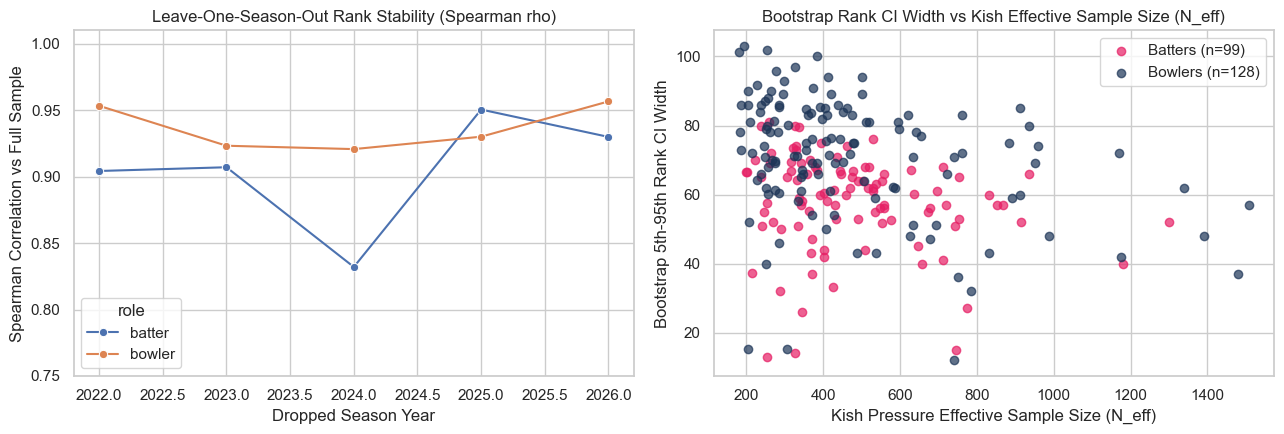

In [4]:
b_bat = pd.read_csv(OUT_V2 / 'bootstrap_results_batters.csv')
b_bowl = pd.read_csv(OUT_V2 / 'bootstrap_results_bowlers.csv')
all_bat = pd.read_csv(OUT_V2 / 'all_batter_rankings.csv')
all_bowl = pd.read_csv(OUT_V2 / 'all_bowler_rankings.csv')

print('Top-10 Batters bootstrap audit (n_boot=1000):')
print(b_bat[b_bat['rank'] <= 10].sort_values('rank')[['rank', 'player_name', 'valid_eligible_iters', 'ineligible_iters', 'absent_iters', 'boot_median_rank', 'boot_p05_rank', 'boot_p95_rank', 'boot_ci_width', 'top10_inclusion_frequency']].round(3).to_string(index=False))

print('\nTop-10 Bowlers bootstrap audit (n_boot=1000):')
print(b_bowl[b_bowl['rank'] <= 10].sort_values('rank')[['rank', 'player_name', 'valid_eligible_iters', 'ineligible_iters', 'absent_iters', 'boot_median_rank', 'boot_p05_rank', 'boot_p95_rank', 'boot_ci_width', 'top10_inclusion_frequency']].round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.lineplot(data=loso_s, x='dropped_season', y='spearman_rho', hue='role', marker='o', ax=axes[0])
axes[0].set_ylim(0.75, 1.01)
axes[0].set_title('Leave-One-Season-Out Rank Stability (Spearman rho)')
axes[0].set_xlabel('Dropped Season Year')
axes[0].set_ylabel('Spearman Correlation vs Full Sample')

axes[1].scatter(all_bat['pressure_neff'], all_bat['boot_ci_width'], alpha=0.7, color='#E61E64', label='Batters (n=99)')
axes[1].scatter(all_bowl['pressure_neff'], all_bowl['boot_ci_width'], alpha=0.7, color='#1D3557', label='Bowlers (n=128)')
axes[1].set_title('Bootstrap Rank CI Width vs Kish Effective Sample Size (N_eff)')
axes[1].set_xlabel('Kish Pressure Effective Sample Size (N_eff)')
axes[1].set_ylabel('Bootstrap 5th-95th Rank CI Width')
axes[1].legend()
plt.tight_layout()
plt.show()